In [1]:
!pip install pytorch-tabnet


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: C:\Python313\python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import time
import json
import pickle
import torch
from pytorch_tabnet.tab_model import TabNetClassifier
from pytorch_tabnet.metrics import Accuracy, BalancedAccuracy
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
data_dir = "../data/processed/"

# Tải dữ liệu đã tiền xử lý — dùng dữ liệu GỐC (không SMOTE)
X_train = pd.read_csv(data_dir + "X_train.csv")
X_val   = pd.read_csv(data_dir + "X_val.csv")
X_test  = pd.read_csv(data_dir + "X_test.csv")

y_train = pd.read_csv(data_dir + "y_train.csv").values.ravel()
y_val   = pd.read_csv(data_dir + "y_val.csv").values.ravel()
y_test  = pd.read_csv(data_dir + "y_test.csv").values.ravel()

# Tải label encoder — 8 lớp gốc
with open(data_dir + "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

print(f"Train set: {X_train.shape}, Labels: {y_train.shape}")
print(f"Validation set: {X_val.shape}, Labels: {y_val.shape}")
print(f"Test set: {X_test.shape}, Labels: {y_test.shape}")
print(f"Số lớp: {len(np.unique(y_train))}")
print(f"Số features: {X_train.shape[1]}")

# Mapping nhãn
label_names = label_encoder.classes_
print(f"\nNhãn các lớp:")
for idx, name in enumerate(label_names):
    print(f"  {idx}: {name}")

Train set: (224107, 78), Labels: (224107,)
Validation set: (47868, 78), Labels: (47868,)
Test set: (47996, 78), Labels: (47996,)
Số lớp: 8
Số features: 78

Nhãn các lớp:
  0: attackfree
  1: dosattack
  2: floodattack
  3: fuzzyattack
  4: iec104starvationattack
  5: mitmattack
  6: ntpddosattack
  7: portscanattack


In [3]:
# Tham số TabNet
tabnet_params = {
    "n_d": 64,                    # Width của decision prediction layer
    "n_a": 64,                    # Width của attention embedding
    "n_steps": 5,                 # Số bước decision trong mô hình
    "gamma": 1.5,                 # Hệ số cho feature reusage trong attention
    "n_independent": 2,           # Số independent GLU layers tại mỗi bước
    "n_shared": 2,                # Số shared GLU layers tại mỗi bước
    "lambda_sparse": 1e-4,        # Sparsity regularization
    "momentum": 0.02,              # Momentum cho batch normalization
    "clip_value": 2.0,            # Gradient clipping
    "optimizer_fn": torch.optim.Adam,
    "optimizer_params": dict(lr=2e-2),
    "scheduler_fn": torch.optim.lr_scheduler.StepLR,  # Đổi sang StepLR
    "scheduler_params": {
        "step_size": 10,          # Giảm LR sau mỗi 10 epochs
        "gamma": 0.9              # Nhân LR với 0.9
    },
    "mask_type": "entmax",        # Loại attention mask (sparsemax hoặc entmax)
    "verbose": 1,
    "seed": 42
}

print("Tham số TabNet:")
for key, value in tabnet_params.items():
    if not callable(value) and not isinstance(value, dict):
        print(f"  {key}: {value}")


Tham số TabNet:
  n_d: 64
  n_a: 64
  n_steps: 5
  gamma: 1.5
  n_independent: 2
  n_shared: 2
  lambda_sparse: 0.0001
  momentum: 0.02
  clip_value: 2.0
  mask_type: entmax
  verbose: 1
  seed: 42


In [5]:
# Khởi tạo mô hình
model = TabNetClassifier(**tabnet_params)

In [6]:
timing = {}   # dict lưu toàn bộ thời gian đo được trong notebook này
 
# --- Đo thời gian huấn luyện TabNet ---
t0 = time.perf_counter()
 
model.fit(
    X_train=X_train.values,
    y_train=y_train,
    eval_set=[(X_train.values, y_train), (X_val.values, y_val)],
    eval_name=["train", "valid"],
    eval_metric=["accuracy", "balanced_accuracy"],
    max_epochs=100,
    patience=15,
    batch_size=1024,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False
)
 
timing['tabnet_training_sec'] = time.perf_counter() - t0
n_epochs_actual = len(model.history.history['loss'])
timing['tabnet_epochs_actual'] = n_epochs_actual
timing['tabnet_sec_per_epoch'] = timing['tabnet_training_sec'] / n_epochs_actual
 
print(f"Thời gian huấn luyện TabNet: {timing['tabnet_training_sec']:.1f}s "
      f"({n_epochs_actual} epochs, {timing['tabnet_sec_per_epoch']:.2f}s/epoch)")
 
# Lưu ngay để dùng lại ở notebook XAI (không cần train lại để lấy con số này)
with open(data_dir + 'timing_training.json', 'w', encoding='utf-8') as f:
    json.dump(timing, f, indent=4)
print(f"✓ Đã lưu: {data_dir}timing_training.json")

epoch 0  | loss: 0.11169 | train_accuracy: 0.99535 | train_balanced_accuracy: 0.71934 | valid_accuracy: 0.99453 | valid_balanced_accuracy: 0.70805 |  0:02:38s
epoch 1  | loss: 0.01821 | train_accuracy: 0.99511 | train_balanced_accuracy: 0.70925 | valid_accuracy: 0.9944  | valid_balanced_accuracy: 0.70612 |  0:04:47s
epoch 2  | loss: 0.01632 | train_accuracy: 0.9958  | train_balanced_accuracy: 0.79034 | valid_accuracy: 0.99494 | valid_balanced_accuracy: 0.75982 |  0:07:10s
epoch 3  | loss: 0.01572 | train_accuracy: 0.99564 | train_balanced_accuracy: 0.81733 | valid_accuracy: 0.9949  | valid_balanced_accuracy: 0.77729 |  0:09:57s
epoch 4  | loss: 0.01428 | train_accuracy: 0.99601 | train_balanced_accuracy: 0.95157 | valid_accuracy: 0.99524 | valid_balanced_accuracy: 0.89405 |  0:12:11s
epoch 5  | loss: 0.01345 | train_accuracy: 0.99585 | train_balanced_accuracy: 0.86079 | valid_accuracy: 0.99497 | valid_balanced_accuracy: 0.83089 |  0:14:22s
epoch 6  | loss: 0.01355 | train_accuracy: 0.9

In [7]:
import json

history_to_save = {k: [float(x) for x in v] 
                   for k, v in model.history.history.items()}

with open(data_dir + 'training_history.json', 'w') as f:
    json.dump(history_to_save, f)

print("Đã lưu history")
print("Keys:", list(history_to_save.keys()))

Đã lưu history
Keys: ['loss', 'lr', 'train_accuracy', 'train_balanced_accuracy', 'valid_accuracy', 'valid_balanced_accuracy']


In [8]:
# Lưu mô hình — KHÔNG thêm .zip vào tên
model_path = data_dir + "tabnet_iec104_model"
model.save_model(model_path)
# File thực tế sẽ là: tabnet_iec104_model.zip
print(f"Đã lưu tại: {model_path}.zip")

Successfully saved model at ../data/processed/tabnet_iec104_model.zip
Đã lưu tại: ../data/processed/tabnet_iec104_model.zip


In [9]:
# Dự đoán trên tập test
y_pred = model.predict(X_test.values)
y_pred_proba = model.predict_proba(X_test.values)

In [10]:
# 1. Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"\n1. ACCURACY: {acc:.4f} ({acc*100:.2f}%)")

# 2. Precision, Recall, F1-Score
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, average=None, labels=range(len(label_names))
)

# 3. AUC (One-vs-Rest)
try:
    from sklearn.preprocessing import label_binarize
    y_test_bin = label_binarize(y_test, classes=range(len(label_names)))
    
    # AUC cho từng lớp
    auc_scores = []
    for i in range(len(label_names)):
        try:
            auc = roc_auc_score(y_test_bin[:, i], y_pred_proba[:, i])
            auc_scores.append(auc)
        except:
            auc_scores.append(np.nan)
    
    # AUC macro và weighted
    macro_auc = np.nanmean(auc_scores)
    weighted_auc = np.average([auc_scores[i] for i in range(len(auc_scores)) if not np.isnan(auc_scores[i])], 
                               weights=[support[i] for i in range(len(support)) if not np.isnan(auc_scores[i])])
except Exception as e:
    print(f"\nCảnh báo: Không thể tính AUC - {e}")
    auc_scores = [np.nan] * len(label_names)
    macro_auc = np.nan
    weighted_auc = np.nan

print("\n2. CHI TIẾT THEO TỪNG LỚP:")
print("-" * 100)
print(f"{'Class':<25} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'AUC':<12} {'Support':<10}")
print("-" * 100)
for idx, name in enumerate(label_names):
    auc_str = f"{auc_scores[idx]:.4f}" if not np.isnan(auc_scores[idx]) else "N/A"
    print(f"{name:<25} {precision[idx]:<12.4f} {recall[idx]:<12.4f} "
          f"{f1[idx]:<12.4f} {auc_str:<12} {support[idx]:<10}")
print("-" * 100)

# Macro và Weighted averages
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average='macro'
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average='weighted'
)

print(f"\n3. TRUNG BÌNH:")
print("-" * 100)
print(f"{'Metric':<25} {'Macro Avg':<15} {'Weighted Avg':<15}")
print("-" * 100)
print(f"{'Precision':<25} {macro_p:<15.4f} {weighted_p:<15.4f}")
print(f"{'Recall':<25} {macro_r:<15.4f} {weighted_r:<15.4f}")
print(f"{'F1-Score':<25} {macro_f1:<15.4f} {weighted_f1:<15.4f}")
auc_macro_str = f"{macro_auc:.4f}" if not np.isnan(macro_auc) else "N/A"
auc_weighted_str = f"{weighted_auc:.4f}" if not np.isnan(weighted_auc) else "N/A"
print(f"{'AUC':<25} {auc_macro_str:<15} {auc_weighted_str:<15}")
print("-" * 100)


1. ACCURACY: 0.9962 (99.62%)

2. CHI TIẾT THEO TỪNG LỚP:
----------------------------------------------------------------------------------------------------
Class                     Precision    Recall       F1-Score     AUC          Support   
----------------------------------------------------------------------------------------------------
attackfree                0.9474       0.9474       0.9474       1.0000       38        
dosattack                 0.9964       1.0000       0.9982       0.9994       45694     
floodattack               0.8667       0.8125       0.8387       1.0000       16        
fuzzyattack               0.9592       1.0000       0.9792       1.0000       141       
iec104starvationattack    0.9836       0.9836       0.9836       0.9977       304       
mitmattack                0.4000       0.5000       0.4444       0.9999       4         
ntpddosattack             0.9971       0.9971       0.9971       1.0000       342       
portscanattack            1.

In [11]:
cm = confusion_matrix(y_test, y_pred)

# Tính % theo hàng (recall per class)
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

# Tạo annotation kết hợp số + %
annot = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = cm[i, j]
        pct = cm_percent[i, j]
        if count == 0:
            annot[i, j] = ''
        elif i == j:
            annot[i, j] = f'{count}\n({pct:.1f}%)'
        else:
            annot[i, j] = f'{count}\n({pct:.1f}%)'

plt.figure(figsize=(13, 10))

# Dùng log scale cho màu để các lớp nhỏ vẫn thấy rõ
from matplotlib.colors import LogNorm
mask_zero = (cm == 0)

ax = sns.heatmap(
    cm,
    annot=annot,
    fmt='',
    cmap='Blues',
    norm=LogNorm(vmin=1, vmax=cm.max()),
    xticklabels=label_names,
    yticklabels=label_names,
    linewidths=0.5,
    linecolor='gray',
    cbar_kws={'label': 'Count (log scale)'},
    mask=mask_zero   # ô = 0 thì để trắng
)

# Viền đỏ cho các ô diagonal (đúng)
for i in range(len(label_names)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, 
                                edgecolor='red', lw=2))

plt.title('Confusion Matrix — TabNet on SANDI-2024/IEC 104', fontsize=14, pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.savefig(data_dir + 'confusion_matrix.png', dpi=300, bbox_inches='tight')
print(f"✓ Đã lưu confusion matrix")
plt.close()

✓ Đã lưu confusion matrix


In [12]:
feature_importances = model.feature_importances_
feature_names = X_train.columns

# Sắp xếp theo độ quan trọng
indices = np.argsort(feature_importances)[::-1]

print("\nTop 20 features quan trọng nhất:")
for i, idx in enumerate(indices[:20], 1):
    print(f"{i:2d}. {feature_names[idx]:<40} {feature_importances[idx]:.6f}")

# Vẽ biểu đồ feature importance
plt.figure(figsize=(12, 8))
top_n = 20
top_indices = indices[:top_n]
plt.barh(range(top_n), feature_importances[top_indices])
plt.yticks(range(top_n), [feature_names[i] for i in top_indices])
plt.xlabel('Importance Score', fontsize=12)
plt.title(f'Top {top_n} Feature Importances - TabNet', fontsize=14, pad=20)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(data_dir + 'feature_importance.png', dpi=300, bbox_inches='tight')
print(f"\nĐã lưu feature importance tại: {data_dir}feature_importance.png")
plt.close()



Top 20 features quan trọng nhất:
 1. Fwd Header Length                        0.120643
 2. Fwd IAT Min                              0.120452
 3. Bwd Header Length                        0.077061
 4. Flow IAT Std                             0.069189
 5. RST Flag Count                           0.066794
 6. Flow IAT Min                             0.050515
 7. Total Fwd Packet                         0.046787
 8. Fwd IAT Total                            0.042353
 9. Down/Up Ratio                            0.037717
10. Fwd Packets/s                            0.034892
11. Fwd Packet Length Std                    0.034087
12. Fwd IAT Max                              0.032435
13. Flow Duration                            0.024770
14. CWR Flag Count                           0.020423
15. URG Flag Count                           0.019829
16. Idle Max                                 0.018943
17. Flow Packets/s                           0.018633
18. ACK Flag Count                           0.0

In [13]:
try:
    history_dict = model.history.history
    print("Keys thực tế:", list(history_dict.keys()))  # giữ lại để debug

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history_dict['train_balanced_accuracy'], 
            label='Train Balanced Acc', linewidth=2, color='steelblue')
    plt.plot(history_dict['valid_balanced_accuracy'], 
            label='Validation Balanced Acc', linewidth=2,
            linestyle='--', color='orange', marker='o', markersize=3)
    plt.title('Training and Validation Balanced Accuracy', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Balanced Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)

   # Accuracy curve
    plt.subplot(1, 2, 2)
    if 'train_accuracy' in history_dict:
        plt.plot(history_dict['train_accuracy'], 
                 label='Train Accuracy', linewidth=2, 
                 color='steelblue', alpha=0.9)
    if 'valid_accuracy' in history_dict:
        plt.plot(history_dict['valid_accuracy'], 
                label='Validation Accuracy', linewidth=2,
                linestyle='--', color='orange', 
                alpha=0.9, marker='o', markersize=3)  # thêm marker nhỏ

    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.title('Training and Validation Accuracy', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(data_dir + 'learning_curves.png', dpi=300, bbox_inches='tight')
    print(f"✓ Đã lưu learning curves tại: {data_dir}learning_curves.png")
    plt.close()

except Exception as e:
    print(f"Lỗi: {e}")
    print("Keys:", list(model.history.history.keys()))

Keys thực tế: ['loss', 'lr', 'train_accuracy', 'train_balanced_accuracy', 'valid_accuracy', 'valid_balanced_accuracy']
✓ Đã lưu learning curves tại: ../data/processed/learning_curves.png


Keys thực tế: ['loss', 'lr', 'train_accuracy', 'train_balanced_accuracy', 'valid_accuracy', 'valid_balanced_accuracy']


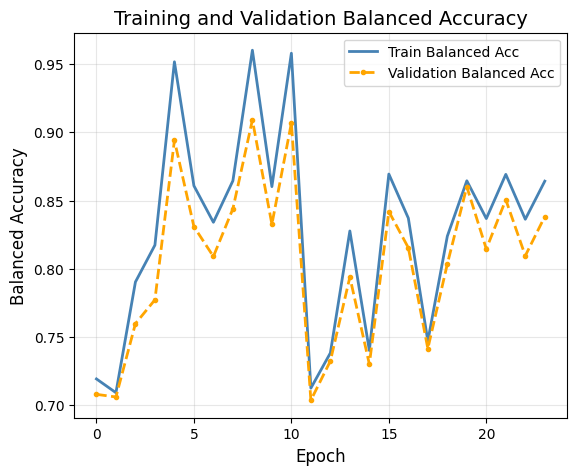

In [14]:
try:
    history_dict = model.history.history
    print("Keys thực tế:", list(history_dict.keys()))  # giữ lại để debug

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history_dict['train_balanced_accuracy'], 
            label='Train Balanced Acc', linewidth=2, color='steelblue')
    plt.plot(history_dict['valid_balanced_accuracy'], 
            label='Validation Balanced Acc', linewidth=2,
            linestyle='--', color='orange', marker='o', markersize=3)
    plt.title('Training and Validation Balanced Accuracy', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Balanced Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
except Exception as e:
    print(f"Lỗi: {e}")
    print("Keys:", list(model.history.history.keys()))

In [15]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Lấy xác suất dự đoán
y_prob = model.predict_proba(X_test.values)

# Binarize nhãn
classes = sorted(np.unique(y_test))
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(10, 8))

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=1.5, 
             label=f'{label_names[i]} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Đường cong ROC đa lớp — TabNet trên SANDI-2024/IEC 104', fontsize=13)
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(data_dir + 'roc_curve.png', dpi=300, bbox_inches='tight')
print("✓ Đã lưu ROC curve")
plt.close()

✓ Đã lưu ROC curve


In [16]:
# Lưu kết quả vào file
results = {
    'accuracy': float(acc),
    'macro_avg': {
        'precision': float(macro_p),
        'recall': float(macro_r),
        'f1_score': float(macro_f1),
        'auc': float(macro_auc) if not np.isnan(macro_auc) else None
    },
    'weighted_avg': {
        'precision': float(weighted_p),
        'recall': float(weighted_r),
        'f1_score': float(weighted_f1),
        'auc': float(weighted_auc) if not np.isnan(weighted_auc) else None
    },
    'per_class_metrics': {
        label_names[i]: {
            'precision': float(precision[i]),
            'recall': float(recall[i]),
            'f1_score': float(f1[i]),
            'auc': float(auc_scores[i]) if not np.isnan(auc_scores[i]) else None,
            'support': int(support[i])
        }
        for i in range(len(label_names))
    },
    'confusion_matrix': cm.tolist()
}

import json
with open(data_dir + 'results_smote.json', 'w') as f:
    json.dump(results, f, indent=4)

print(f" Đã lưu kết quả tại: {data_dir}results.json")

 Đã lưu kết quả tại: ../data/processed/results.json


In [17]:
print(f"\nCÁC CHỈ SỐ ĐÁNH GIÁ CHÍNH:")
print(f"  Accuracy:          {acc*100:.2f}%")
print(f"  Macro Precision:   {macro_p:.4f}")
print(f"  Macro Recall:      {macro_r:.4f}")
print(f"  Macro F1-Score:    {macro_f1:.4f}")
auc_display = f"{macro_auc:.4f}" if not np.isnan(macro_auc) else "N/A"
print(f"  Macro AUC:         {auc_display}")
print(f"\nCác file đã được lưu:")
print(f"  Mô hình: {model_path}")
print(f"  Confusion Matrix: {data_dir}confusion_matrix.png")
print(f"  Feature Importance: {data_dir}feature_importance.png")
print(f"  Learning Curves: {data_dir}learning_curves.png")
print(f"  Kết quả JSON: {data_dir}results.json")
print("\n" + "=" * 60)


CÁC CHỈ SỐ ĐÁNH GIÁ CHÍNH:
  Accuracy:          99.62%
  Macro Precision:   0.8938
  Macro Recall:      0.8905
  Macro F1-Score:    0.8908
  Macro AUC:         0.9995

Các file đã được lưu:
  Mô hình: ../data/processed/tabnet_iec104_model
  Confusion Matrix: ../data/processed/confusion_matrix.png
  Feature Importance: ../data/processed/feature_importance.png
  Learning Curves: ../data/processed/learning_curves.png
  Kết quả JSON: ../data/processed/results.json

